# ДЗ3. Метрики, порог и калибровка

Предсказываю, опоздает ли заказ. Таргет `is_late`:
1 — заказ опоздал, 0 — доставлен вовремя

Сравниваю две модели HistGradientBoostingClassifier:
- модель A — с обычными весами классов;
- модель B — с `class_weight="balanced"`

Данные разделены на train, validation и test в пропорции 60/20/20.
На validation выбираю порог и обучаю калибровку,
на test показываю итоговые метрики.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    average_precision_score,
    precision_recall_curve,
    brier_score_loss,
    log_loss,
)

SEED = 42

data = pd.read_csv("data/olist_delivery_clean.csv")

print("Размер данных:", data.shape)
display(data.head())
display(data["is_late"].value_counts())

Размер данных: (96470, 22)


,order_purchase_timestamp,customer_unique_id,seller_id,customer_state,seller_state,same_state,distance_km,estimated_delivery_days,shipping_limit_days,n_items,...,total_price,total_freight,freight_share,product_category,product_weight_g,product_volume_cm3,payment_type,payment_installments,payment_value,is_late
0,2016-09-15 12:16:38,830d5b7aaa3b6f1e9ad63703bec97d23,ecccfa2bb93b34a3bf033cc5d1dcdc69,SP,PR,0,566.040211,18.488449,4.454803,3,...,134.97,8.49,0.059180,beleza_saude,1000.0,4096.0,NaN,NaN,NaN,1
1,2016-10-03 09:44:50,32ea3bdedab835c3aa6cb68ce66565ef,522620dcb18a6b31cd7bdf73665113a9,SP,PR,0,708.535291,23.593866,18.279514,1,...,29.90,15.56,0.342279,relogios_presentes,300.0,4096.0,boleto,1.0,45.46,0
2,2016-10-03 16:56:50,2f64e403852e6893ae37485d5fcacdaf,f09b760d23495ac9a7e00d29b769007c,RS,SP,0,915.734331,34.293866,17.983981,1,...,21.90,17.19,0.439754,esporte_lazer,400.0,4096.0,boleto,1.0,39.09,0
3,2016-10-03 21:13:36,61db744d2f835035a5625b59350c6b63,45d33f715e24d15a6ccf5c17b3a23e3c,RS,SP,0,818.048765,56.115556,17.795023,1,...,36.49,17.24,0.320864,esporte_lazer,767.0,4160.0,boleto,1.0,53.73,0
4,2016-10-03 22:06:03,8d3a54507421dbd2ce0a1d58046826e0,cca3071e3e9bb7d12640c9fbe2301306,SP,SP,1,212.149919,50.079132,17.761840,1,...,119.90,13.56,0.101603,moveis_decoracao,2050.0,14960.0,credit_card,6.0,133.46,0


is_late
0    88644
1     7826
Name: count, dtype: int64

In [2]:
excluded_columns = [
    "order_purchase_timestamp",
    "customer_unique_id",
    "seller_id",
    "is_late",
]

X = data.drop(columns=excluded_columns).copy()
y = data["is_late"]

category_columns = [
    "customer_state",
    "seller_state",
    "product_category",
    "payment_type",
]

for column in category_columns:
    X[column] = X[column].astype("category")

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.4,
    stratify=y,
    random_state=SEED,
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp,
    random_state=SEED,
)

split_info = pd.DataFrame({
    "часть": ["train", "validation", "test"],
    "количество": [len(y_train), len(y_val), len(y_test)],
    "доля опозданий": [y_train.mean(), y_val.mean(), y_test.mean()],
})

display(split_info)
print("Количество признаков:", X.shape[1])

,часть,количество,доля опозданий
0,train,57882,0.081131
1,validation,19294,0.081113
2,test,19294,0.081113


Количество признаков: 18


In [3]:
model_a = HistGradientBoostingClassifier(random_state=SEED)

model_a.fit(X_train, y_train)

p_val_a = model_a.predict_proba(X_val)[:, 1]
p_test_a = model_a.predict_proba(X_test)[:, 1]
p_constant = np.full(len(y_test), y_train.mean())

comparison = pd.DataFrame([
    {
        "модель": "A",
        "roc-auc": roc_auc_score(y_test, p_test_a),
        "Average Precision": average_precision_score(y_test, p_test_a),
    },
    {
        "модель": "Константа",
        "roc-auc": roc_auc_score(y_test, p_constant),
        "Average Precision": average_precision_score(y_test, p_constant),
    },
])

display(comparison.round(4))

,модель,roc-auc,Average Precision
0,A,0.7235,0.2125
1,Константа,0.5000,0.0811


In [4]:
pred_05 = (p_test_a >= 0.5).astype(int)

metrics_05 = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, pred_05),
    "precision": precision_score(y_test, pred_05, zero_division=0),
    "recall": recall_score(y_test, pred_05, zero_division=0),
    "F1": f1_score(y_test, pred_05, zero_division=0),
}])

matrix_05 = pd.DataFrame(
    confusion_matrix(y_test, pred_05),
    index=["Факт: вовремя", "Факт: опоздал"],
    columns=["Прогноз: вовремя", "Прогноз: опоздал"],
)

display(metrics_05.round(4))
display(matrix_05)

,accuracy,precision,recall,F1
0,0.9189,0.5294,0.0058,0.0114


,Прогноз: вовремя,Прогноз: опоздал
Факт: вовремя,17721,8
Факт: опоздал,1556,9


При пороге 0.5 accuracy модели составляет 0.9189,
precision — 0.5294, recall — 0.0058

Поскольку опозданий около 8%, высокая accuracy сама по себе не показывает,
насколько хорошо модель находит опоздания. Для этого обращаемся к precision, recall и матрицу ошибок

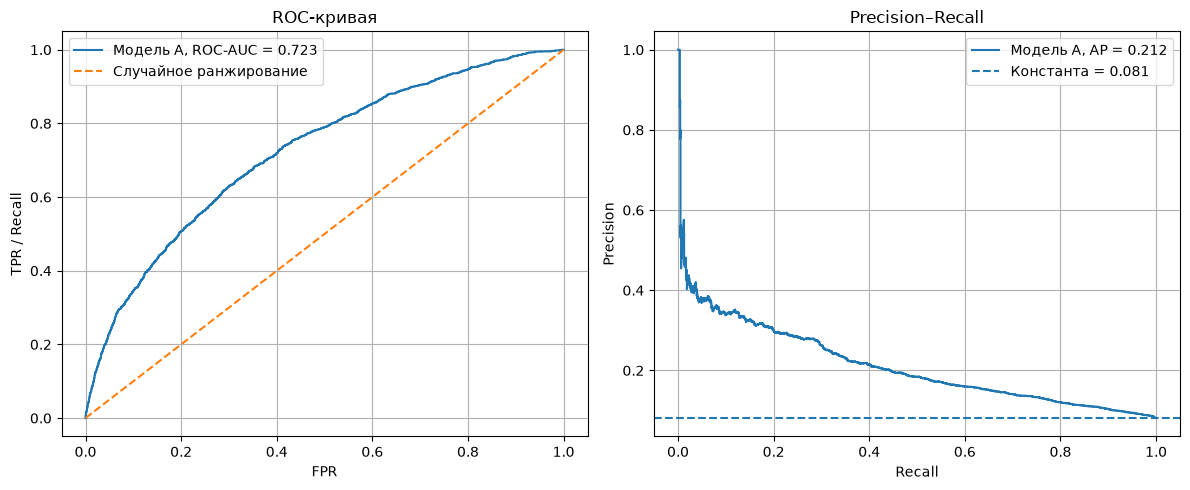

In [5]:
fpr, tpr, _ = roc_curve(y_test, p_test_a)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, p_test_a)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    fpr,
    tpr,
    label=f"Модель A, ROC-AUC = {roc_auc_score(y_test, p_test_a):.3f}",
)
axes[0].plot([0, 1], [0, 1], "--", label="Случайное ранжирование")
axes[0].set_title("ROC-кривая")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR / Recall")
axes[0].legend()
axes[0].grid()

axes[1].plot(
    recall_curve,
    precision_curve,
    label=f"Модель A, AP = {average_precision_score(y_test, p_test_a):.3f}",
)
axes[1].axhline(
    y_test.mean(),
    linestyle="--",
    label=f"Константа = {y_test.mean():.3f}",
)
axes[1].set_title("Precision–Recall")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

In [6]:
def threshold_for_capacity(probabilities, max_share=0.10):
    scores = np.sort(np.asarray(probabilities))[::-1]

    max_orders = int(len(scores) * max_share)
    threshold = np.nextafter(scores[max_orders], np.inf)

    return threshold


def threshold_for_best_f1(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities,
    )

    numerator = 2 * precision[:-1] * recall[:-1]
    denominator = precision[:-1] + recall[:-1]

    f1_values = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator),
        where=denominator != 0,
    )

    return thresholds[np.argmax(f1_values)]


def threshold_results(y_valid, p_valid, y_test, p_test, threshold, name):
    valid_predictions = (p_valid >= threshold).astype(int)
    test_predictions = (p_test >= threshold).astype(int)

    return {
        "вариант": name,
        "порог": threshold,
        "доля на validation": valid_predictions.mean(),
        "доля на test": test_predictions.mean(),
        "precision на test": precision_score(
            y_test, test_predictions, zero_division=0
        ),
        "recall на test": recall_score(
            y_test, test_predictions, zero_division=0
        ),
        "F1 на test": f1_score(
            y_test, test_predictions, zero_division=0
        ),
    }

In [7]:
threshold_a_capacity = threshold_for_capacity(p_val_a)
threshold_a_f1 = threshold_for_best_f1(y_val, p_val_a)

threshold_a_table = pd.DataFrame([
    threshold_results(
        y_val, p_val_a, y_test, p_test_a,
        threshold_a_capacity,
        "A: ограничение 10%",
    ),
    threshold_results(
        y_val, p_val_a, y_test, p_test_a,
        threshold_a_f1,
        "A: максимальный F1",
    ),
])

display(threshold_a_table.round(4))

,вариант,порог,доля на validation,доля на test,precision на test,recall на test,F1 на test
0,A: ограничение 10%,0.1693,0.10,0.1000,0.2514,0.3099,0.2776
1,A: максимальный F1,0.1283,0.17,0.1711,0.2032,0.4288,0.2757


При пороге около 0.1693, выбранном с ограничением на validation,
модель отмечает на test примерно 10% заказов

Precision = 0.2514 означает, что среди отмеченных заказов
25.14% заказов действительно опоздали. Recall = 0.3099 означает,
что модель нашла 30.99% всех реально опоздавших заказов

Порог около 0.1283, выбранный по максимальному F1 на validation,
отмечает на test 17.11% заказов

In [9]:
model_b = HistGradientBoostingClassifier(
    random_state=SEED,
    class_weight="balanced",
)

model_b.fit(X_train, y_train)

p_val_b = model_b.predict_proba(X_val)[:, 1]
p_test_b = model_b.predict_proba(X_test)[:, 1]

In [10]:
calibrated_models = {}

for model_name, model in [("A", model_a), ("B", model_b)]:
    for method in ["sigmoid", "isotonic"]:
        calibrated = CalibratedClassifierCV(
            estimator=FrozenEstimator(model),
            method=method,
        )

        calibrated.fit(X_val, y_val)

        calibrated_models[(model_name, method)] = calibrated

print("Обучено калибровок:", len(calibrated_models))

Обучено калибровок: 4


In [11]:
test_probabilities = {
    "A: без калибровки": p_test_a,
    "A: Платт": calibrated_models[("A", "sigmoid")].predict_proba(X_test)[:, 1],
    "A: изотоническая": calibrated_models[("A", "isotonic")].predict_proba(X_test)[:, 1],
    "B: без калибровки": p_test_b,
    "B: Платт": calibrated_models[("B", "sigmoid")].predict_proba(X_test)[:, 1],
    "B: изотоническая": calibrated_models[("B", "isotonic")].predict_proba(X_test)[:, 1],
}

calibration_results = []

for name, probabilities in test_probabilities.items():
    calibration_results.append({
        "вариант": name,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Average Precision": average_precision_score(y_test, probabilities),
        "Brier score": brier_score_loss(y_test, probabilities),
        "Log loss": log_loss(y_test, probabilities),
        "средняя вероятность": probabilities.mean(),
    })

calibration_table = pd.DataFrame(calibration_results)

display(calibration_table.round(4))

,вариант,ROC-AUC,Average Precision,Brier score,Log loss,средняя вероятность
0,A: без калибровки,0.7235,0.2125,0.0697,0.2555,0.0807
1,A: Платт,0.7235,0.2125,0.0697,0.2556,0.0808
2,A: изотоническая,0.7220,0.2001,0.0699,0.2577,0.0808
3,B: без калибровки,0.7216,0.2054,0.1925,0.5652,0.4056
4,B: Платт,0.7216,0.2054,0.0700,0.2567,0.0806
5,B: изотоническая,0.7213,0.1964,0.0701,0.2567,0.0809


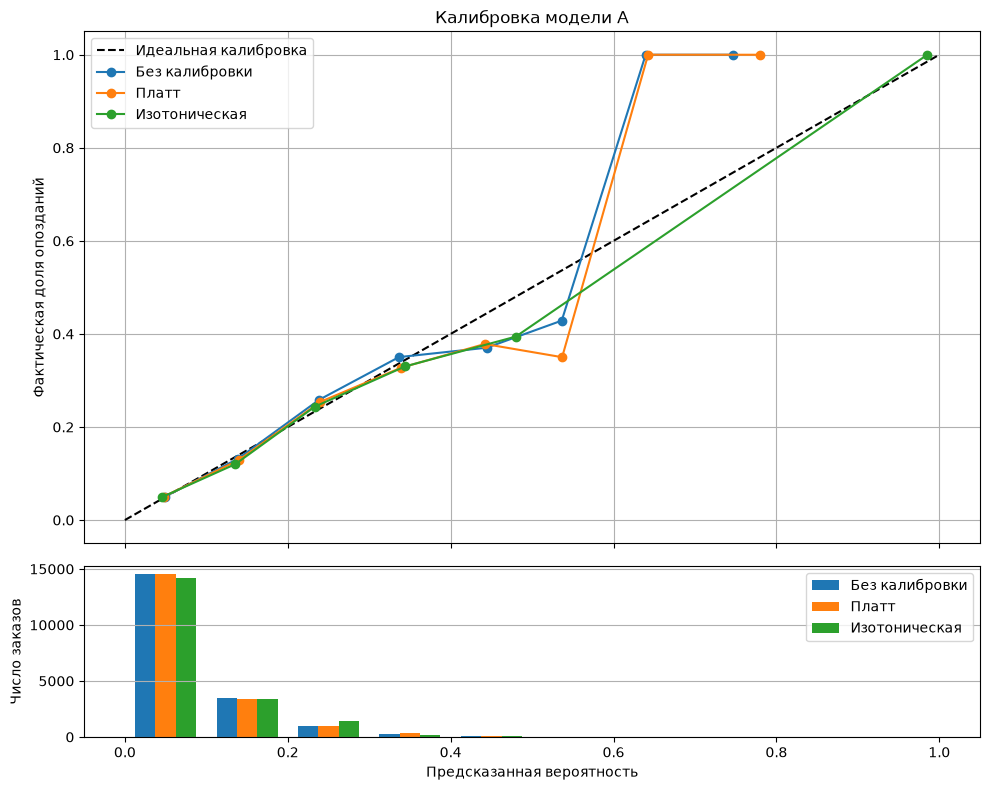

Количество заказов в интервалах для модели A:


,интервал,Без калибровки,Платт,Изотоническая
0,0.0–0.1,14506,14504,14179
1,0.1–0.2,3465,3372,3352
2,0.2–0.3,975,988,1448
3,0.3–0.4,277,330,209
4,0.4–0.5,54,74,104
5,0.5–0.6,14,20,0
6,0.6–0.7,2,5,0
7,0.7–0.8,1,1,0
8,0.8–0.9,0,0,0
9,0.9–1.0,0,0,2


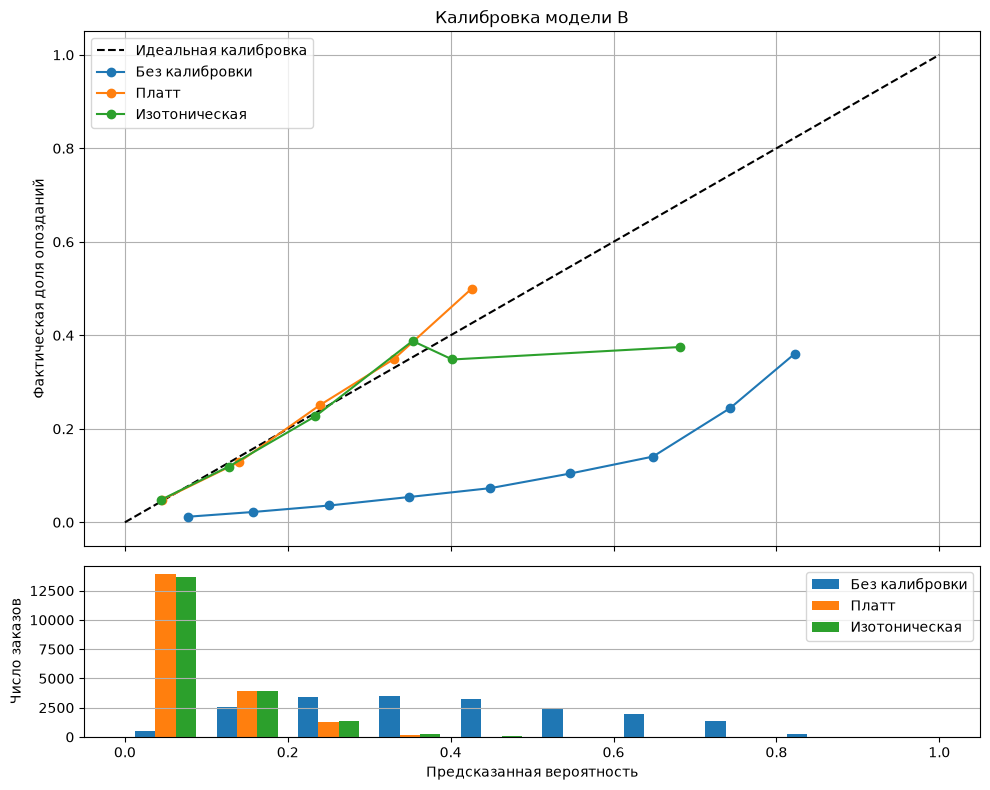

Количество заказов в интервалах для модели B:


,интервал,Без калибровки,Платт,Изотоническая
0,0.0–0.1,501,13947,13655
1,0.1–0.2,2588,3885,3929
2,0.2–0.3,3393,1256,1357
3,0.3–0.4,3476,192,232
4,0.4–0.5,3268,14,89
5,0.5–0.6,2509,0,0
6,0.6–0.7,1963,0,32
7,0.7–0.8,1380,0,0
8,0.8–0.9,216,0,0
9,0.9–1.0,0,0,0


In [ ]:
bin_edges = np.linspace(0, 1, 11)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

for model_name in ["A", "B"]:
    variants = {
        "Без калибровки": test_probabilities[f"{model_name}: без калибровки"],
        "Платт": test_probabilities[f"{model_name}: Платт"],
        "Изотоническая": test_probabilities[f"{model_name}: изотоническая"],
    }

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(10, 8),
        sharex=True,
        gridspec_kw={"height_ratios": [3, 1]},
    )

    axes[0].plot([0, 1], [0, 1], "--", color="black", label="Идеальная калибровка")

    counts_table = pd.DataFrame({
        "интервал": [
            f"{bin_edges[i]:.1f}–{bin_edges[i + 1]:.1f}"
            for i in range(10)
        ]
    })

    for i, (name, probabilities) in enumerate(variants.items()):
        fraction_positive, mean_probability = calibration_curve(
            y_test,
            probabilities,
            n_bins=10,
            strategy="uniform",
        )

        axes[0].plot(mean_probability, fraction_positive, marker="o", label=name)

        bin_numbers = np.searchsorted(
            bin_edges[1:-1],
            probabilities,
            side="left",
        )
        counts = np.bincount(bin_numbers, minlength=10)

        counts_table[name] = counts

        axes[1].bar(
            bin_centers + (i - 1) * 0.025,
            counts,
            width=0.025,
            label=name,
        )

    axes[0].set_title(f"Калибровка модели {model_name}")
    axes[0].set_ylabel("Фактическая доля опозданий")
    axes[0].legend()
    axes[0].grid()

    axes[1].set_xlabel("Предсказанная вероятность")
    axes[1].set_ylabel("Число заказов")
    axes[1].legend()
    axes[1].grid(axis="y")

    plt.tight_layout()
    plt.show()

    print(f"Количество заказов в интервалах для модели {model_name}:")
    display(counts_table)